### Package versions

Run the cell below to record the exact package versions used to generate the results in this notebook.


In [1]:
# --- Environment / package versions (added for reproducibility) ---
import sys
try:
    from importlib.metadata import version, PackageNotFoundError
except ImportError:  # Python < 3.8
    from importlib_metadata import version, PackageNotFoundError
print("Python:", sys.version.split()[0])
for _pkg in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "seaborn", "gseapy", "pyliftover", "openpyxl", "requests", "pyBigWig", "pyreadr", "adjustText", "pypdf"]:
    try:
        print(f"{_pkg}: {version(_pkg)}")
    except PackageNotFoundError:
        pass


Python: 3.10.12
numpy: 2.2.6
pandas: 2.3.3
scipy: 1.15.3
statsmodels: 0.14.6
matplotlib: 3.10.9
seaborn: 0.13.2
gseapy: 1.3.1
openpyxl: 3.1.5
requests: 2.34.2
pyreadr: 0.5.6
adjustText: 1.4.0
pypdf: 6.13.1


# Fig 3H · System A/N glutamine-import programme, SLC38A4-KO vs SAH liver

Log2 fold-change of the hepatocellular glutamine-import machinery in SLC38A4-knockout Huh7.5 cells
(KO vs WT; limma-voom) and in patient liver (SAH vs normal; InTEAM DESeq2), split into three functional
groups: plasma-membrane **System A** transporters (SLC38A4/A2/A1, SNAT4/2/1), the **System N** transporters
SLC38A3 and SLC38A6 (SNAT3/6), and the mitochondrial urea-cycle carriers **SLC25A15** (ornithine) and
**SLC25A13** (aspartate-glutamate). All detected System A and System N SLC38 members and both canonical
mitochondrial urea-cycle carriers are shown; SLC38A5 (SNAT5) and SLC25A2 (ORNT2) were not detected in the
data. Bars are coloured by functional group (red = System A, blue = System N, grey = mitochondrial carrier);
full opacity = KO vs WT, faded = SAH vs normal. Significance is marked at each bar tip (`*` FDR < 0.05;
`ns` = not significant). SLC38A4, SLC38A3, SLC25A15 and SLC25A13 are concordantly downregulated in both
settings; SLC38A2 is significantly reduced in KO with a consistent but non-significant SAH trend. Two
transporters are instead induced in SAH liver: SLC38A1 (SNAT1), significantly reduced in KO and therefore
divergent, and the predominantly neuronal SLC38A6 (SNAT6), unchanged in KO -- both consistent with
stress-driven induction that the mature-hepatocyte import programme otherwise lacks.
Data: built in this notebook from `ReSOLUTE_SLC_ 464_genes_annotation.xlsx` (ReSOLUTE annotation), `Fig3C_limma_KO_vs_WT_combined_mincount10.csv` (KO vs WT, combined clones) and `InTEAM_AH_vs_normal_DESeq2.csv` (SAH vs normal).


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# Compact sizing for placement as one panel in a multi-panel Illustrator figure (~85x70 mm).
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 7, 'axes.linewidth': 0.7,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.major.width': 0.7, 'ytick.major.width': 0.7,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'axes.unicode_minus': False,
})
CAT_C = {'A': '#D73027', 'N': '#4575B4', 'carrier': '#555555'}
SAH_ALPHA = 0.45
SNAT = {'SLC38A4': 'SNAT4', 'SLC38A2': 'SNAT2', 'SLC38A1': 'SNAT1',
        'SLC38A3': 'SNAT3', 'SLC38A6': 'SNAT6'}


In [3]:
# ── Build the ReSOLUTE-annotated SLC differential-expression table from source files ──
# (previously read a pre-merged `SLC_DE_ReSOLUTE_annotated.csv`; rebuilt here in the open,
# from the same raw inputs used elsewhere in this repo, so the join logic is visible.)
_ann = pd.read_excel('ReSOLUTE_SLC_ 464_genes_annotation.xlsx', sheet_name='dataset', header=1)
_ann = _ann.rename(columns={'HGNC symbol': 'symbol'}).drop_duplicates('symbol')

_ko_comb = pd.read_csv('Fig3C_limma_KO_vs_WT_combined_mincount10.csv').rename(
    columns={'gene_symbol': 'symbol', 'logFC': 'KO_logFC', 'adj.P.Val': 'KO_FDR'}).drop_duplicates('symbol')

_sah = pd.read_csv('InTEAM_AH_vs_normal_DESeq2.csv').rename(
    columns={'log2FoldChange': 'SAH_log2FC', 'padj': 'SAH_padj'}).drop_duplicates('symbol')

# Population = ReSOLUTE-annotated SLC genes also detected in the combined KO limma run (292 genes);
# SAH stats joined in afterwards (left join -- 1 gene, SLC35E2A, isn't in the InTEAM SAH results).
slc_de = (_ann.merge(_ko_comb[['symbol', 'KO_logFC', 'KO_FDR']], on='symbol', how='inner')
              .merge(_sah[['symbol', 'SAH_log2FC', 'SAH_padj']], on='symbol', how='left'))
print(f"ReSOLUTE-annotated SLC transporters, measured in the combined KO run: {len(slc_de)}")

slc = slc_de.set_index('symbol')

# Display order, grouped by transport system (top -> bottom).
# All detected System A + System N SLC38 members and both canonical mito urea-cycle carriers.
# (SLC38A5/SNAT5 and SLC25A2/ORNT2 are not detected in the data.)
GROUPS = [
    ('System A',        'A',       ['SLC38A4', 'SLC38A2', 'SLC38A1']),
    ('System N',        'N',       ['SLC38A3', 'SLC38A6']),
    ('Mito.\ncarriers', 'carrier', ['SLC25A15', 'SLC25A13']),
]

rows = []
for gname, cat, genes in GROUPS:
    for g in genes:
        r = slc.loc[g]
        rows.append(dict(gene=g, cat=cat, grp=gname,
                         ko_lfc=r['KO_logFC'], ko_fdr=r['KO_FDR'],
                         sah_lfc=r['SAH_log2FC'], sah_padj=r['SAH_padj']))
t = pd.DataFrame(rows)
n = len(t)
t['y'] = (n - 1) - np.arange(n)
print(t[['gene', 'cat', 'ko_lfc', 'ko_fdr', 'sah_lfc', 'sah_padj']].round(3).to_string(index=False))

ReSOLUTE-annotated SLC transporters, measured in the combined KO run: 292
    gene     cat  ko_lfc  ko_fdr  sah_lfc  sah_padj
 SLC38A4       A  -1.482   0.000   -2.350     0.000
 SLC38A2       A  -0.855   0.000   -0.225     0.401
 SLC38A1       A  -0.330   0.000    2.475     0.000
 SLC38A3       N  -1.052   0.000   -0.899     0.000
 SLC38A6       N  -0.045   0.369    1.231     0.000
SLC25A15 carrier  -0.805   0.000   -0.926     0.001
SLC25A13 carrier  -0.455   0.000   -1.368     0.000


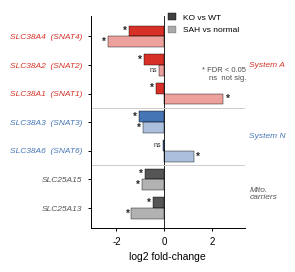

Saved: Fig3H_transporter_concordance.pdf


In [4]:
h = 0.38

def sig_mark(fdr):
    return '*' if fdr < 0.05 else 'ns'

fig, ax = plt.subplots(figsize=(3.35, 2.75))   # compact single panel
for _, r in t.iterrows():
    c = CAT_C[r['cat']]
    ax.barh(r['y']+h/2, r['ko_lfc'],  height=h, color=to_rgba(c, 1.0),       edgecolor='black', lw=0.3)
    ax.barh(r['y']-h/2, r['sah_lfc'], height=h, color=to_rgba(c, SAH_ALPHA), edgecolor='black', lw=0.3)
    for val, yy, fdr in [(r['ko_lfc'], r['y']+h/2, r['ko_fdr']),
                         (r['sah_lfc'], r['y']-h/2, r['sah_padj'])]:
        s = sig_mark(fdr)
        off = 0.09 if val >= 0 else -0.09
        ax.text(val+off, yy, s, va='center', ha='left' if val >= 0 else 'right',
                fontsize=7 if s == '*' else 5,
                fontweight='bold' if s == '*' else 'normal', color='0.15')

ax.axvline(0, color='black', lw=0.6)

labels = [r['gene'] + ('  (' + SNAT[r['gene']] + ')' if r['gene'] in SNAT else '') for _, r in t.iterrows()]
ax.set_yticks(t['y']); ax.set_yticklabels(labels, fontsize=6, fontstyle='italic')
for tick, (_, r) in zip(ax.get_yticklabels(), t.iterrows()):
    tick.set_color(CAT_C[r['cat']])

tr = ax.get_yaxis_transform()
prev = None
for _, r in t.sort_values('y', ascending=False).iterrows():
    if prev is not None and r['grp'] != prev:
        ax.axhline(r['y']+0.5, color='0.8', lw=0.7)
    prev = r['grp']
for gname, cat, genes in GROUPS:
    ys = t[t['grp'] == gname]['y'].values
    ax.text(1.03, (ys.max()+ys.min())/2, gname, transform=tr, fontsize=6,
            va='center', ha='left', color=CAT_C[cat], fontstyle='italic', linespacing=0.9)

ax.set_xlabel('log2 fold-change', fontsize=7.5)
ax.set_ylim(-0.7, n-0.3)
xmax = max(abs(t['ko_lfc']).max(), abs(t['sah_lfc']).max())
ax.set_xlim(-xmax-0.6, xmax+0.9)
ax.set_xticks([-2, 0, 2])

ax.legend(handles=[
    Patch(facecolor='0.25', edgecolor='black', lw=0.3, label='KO vs WT'),
    Patch(facecolor='0.25', alpha=SAH_ALPHA, edgecolor='black', lw=0.3, label='SAH vs normal'),
], loc='upper right', frameon=False, fontsize=6, handlelength=1.0, handleheight=0.9, bbox_to_anchor=(1.01, 1.05))
ax.text(1.01, 0.76, '* FDR < 0.05\nns  not sig.', transform=ax.transAxes,
        fontsize=5.5, ha='right', va='top', color='0.3', linespacing=1.2)

fig.subplots_adjust(left=0.30, right=0.76)
fig.savefig('Fig3H_transporter_concordance.pdf', bbox_inches='tight'); plt.show()
print('Saved: Fig3H_transporter_concordance.pdf')


# Exploratory analysis 1 · Annotation landscape of the `slc_de` table built above

Characterise the available annotation columns before any grouping decisions are made.
Data: the `slc_de` table built above.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import to_rgba

plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 10, 'axes.linewidth': 1.0,
    'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'axes.unicode_minus': False,
})

slc = slc_de.copy()  # reuse the table built in the cell above

print("=== Shape:", slc.shape)
print()
print("=== Columns:")
for c in slc.columns:
    n_null = slc[c].isna().sum()
    n_uniq = slc[c].nunique()
    print(f"  {c!r:45s}  nulls={n_null:4d}  unique={n_uniq:5d}")

print()
print("=== 'substrate class' value counts:")
print(slc['substrate class'].value_counts().to_string())

print()
print("=== 'assigned cluster' value counts:")
print(slc['assigned cluster'].value_counts().to_string())

print()
print("=== 'subcellular localization' value counts:")
print(slc['subcellular localization'].value_counts().to_string())

print()
print("=== 'elevated tissue expression' (first 30):")
print(slc['elevated tissue expression'].value_counts().head(30).to_string())


=== Shape: (292, 42)

=== Columns:
  'sort id'                                      nulls=   0  unique=  292
  'symbol'                                       nulls=   0  unique=  292
  'HGNC previous symbol'                         nulls= 291  unique=    1
  'HGNC identifier'                              nulls=   0  unique=  292
  'note'                                         nulls= 287  unique=    3
  'pseudogene'                                   nulls=   0  unique=    2
  'SLC superfamily membership source'            nulls=   0  unique=    5
  'family'                                       nulls=   0  unique=   67
  'SLC name'                                     nulls=  12  unique=  280
  'Ensembl Transcript ID'                        nulls=   0  unique=  292
  'Transcript Sequence'                          nulls=   0  unique=  292
  'Transcript Length'                            nulls=   0  unique=  220
  'UniProt Accession'                            nulls=   0  unique=  292
  '

# Exploratory analysis 2 · Systematic differential expression of SLC transporters

For all SLC genes detected in both the KO RNA-seq and the InTEAM SAH cohort:
- **KO**: per-clone limma-voom results (KO1 = C12, KO2 = P1.7 vs WT), assessed for
  concordance (same direction, FDR < 0.05 in at least one clone and consistent sign in both).
- **SAH**: InTEAM DESeq2 results (AH vs normal liver).

Data sources:
- `ReSOLUTE_SLC_ 464_genes_annotation.xlsx`, `Fig3C_limma_KO_vs_WT_combined_mincount10.csv`, `InTEAM_AH_vs_normal_DESeq2.csv` — the same three files joined into `slc_de` earlier in this notebook (annotation + combined-clone KO DE + SAH DE)
- `FigS7_limma_KO1_vs_WT_mincount10.csv`, `FigS7_limma_KO2_vs_WT_mincount10.csv` — per-clone limma-voom tables
- `InTEAM_AH_vs_normal_DESeq2.csv` — SAH cohort DESeq2 results

In [6]:
# ── Load per-clone KO results and SAH results ────────────────────────────
ko1_all = pd.read_csv('FigS7_limma_KO1_vs_WT_mincount10.csv').rename(
    columns={'gene_symbol': 'symbol', 'logFC': 'KO1_logFC', 'adj.P.Val': 'KO1_FDR'})
ko2_all = pd.read_csv('FigS7_limma_KO2_vs_WT_mincount10.csv').rename(
    columns={'gene_symbol': 'symbol', 'logFC': 'KO2_logFC', 'adj.P.Val': 'KO2_FDR'})
sah_all = pd.read_csv('InTEAM_AH_vs_normal_DESeq2.csv').rename(
    columns={'log2FoldChange': 'SAH_log2FC'})

# ── Restrict to SLC genes using the annotation + DE table built above ────
# `slc_de` is already the ReSOLUTE-annotated population measured in the combined KO run
# (see the cell that builds it); here we additionally require SAH measurement.
ann_slc = slc_de[slc_de['symbol'].isin(sah_all['symbol'])].copy()
print(f"SLC genes measured in both KO and SAH datasets: {len(ann_slc)}")

# ── Merge per-clone KO stats ──────────────────────────────────────────────
ko1_slc = ko1_all[ko1_all['symbol'].isin(ann_slc['symbol'])][
    ['symbol', 'KO1_logFC', 'KO1_FDR']].drop_duplicates('symbol')
ko2_slc = ko2_all[ko2_all['symbol'].isin(ann_slc['symbol'])][
    ['symbol', 'KO2_logFC', 'KO2_FDR']].drop_duplicates('symbol')
sah_slc = sah_all[sah_all['symbol'].isin(ann_slc['symbol'])][
    ['symbol', 'SAH_log2FC', 'padj']].rename(columns={'padj': 'SAH_padj'}).drop_duplicates('symbol')

df = (ann_slc[['symbol', 'family', 'substrate class', 'subcellular localization',
               'assigned cluster', 'elevated tissue expression']]
      .merge(ko1_slc, on='symbol', how='left')
      .merge(ko2_slc, on='symbol', how='left')
      .merge(sah_slc, on='symbol', how='left'))

FDR_THRESH = 0.05

# ── DE classification ─────────────────────────────────────────────────────
# KO: significant in ≥1 clone, concordant direction in both
df['KO1_sig'] = df['KO1_FDR'] < FDR_THRESH
df['KO2_sig'] = df['KO2_FDR'] < FDR_THRESH
df['KO_concordant_dir'] = np.sign(df['KO1_logFC']) == np.sign(df['KO2_logFC'])
df['KO_DE'] = (df['KO1_sig'] | df['KO2_sig']) & df['KO_concordant_dir']
df['KO_direction'] = np.where(
    df['KO_DE'],
    np.where(df['KO1_logFC'] < 0, 'down', 'up'),
    'ns')

# SAH
df['SAH_sig'] = df['SAH_padj'] < FDR_THRESH
df['SAH_direction'] = np.where(df['SAH_sig'],
    np.where(df['SAH_log2FC'] < 0, 'down', 'up'), 'ns')

# Combined concordance label
def concordance_label(row):
    if row['KO_DE'] and row['SAH_sig']:
        if row['KO_direction'] == row['SAH_direction']:
            return f"concordant_{row['KO_direction']}"
        else:
            return 'divergent'
    elif row['KO_DE']:
        return 'KO_only'
    elif row['SAH_sig']:
        return 'SAH_only'
    else:
        return 'ns_both'

df['concordance'] = df.apply(concordance_label, axis=1)

# ── Summary table ─────────────────────────────────────────────────────────
print("\n=== DE summary across all SLC transporters ===")
print(f"  Measured (KO & SAH):        {len(df)}")
print(f"  DE in KO (concordant clones): {df['KO_DE'].sum()}")
print(f"    of which  up in KO:        {(df['KO_direction']=='up').sum()}")
print(f"    of which  down in KO:      {(df['KO_direction']=='down').sum()}")
print(f"  DE in SAH:                  {df['SAH_sig'].sum()}")
print(f"    of which  up in SAH:      {(df['SAH_direction']=='up').sum()}")
print(f"    of which  down in SAH:    {(df['SAH_direction']=='down').sum()}")
print()
print("=== Concordance breakdown:")
print(df['concordance'].value_counts().to_string())

print("\n=== Clone-level concordance detail for KO-DE genes:")
ko_de = df[df['KO_DE']].copy()
sig_both = (ko_de['KO1_sig'] & ko_de['KO2_sig']).sum()
sig_ko1_only = (ko_de['KO1_sig'] & ~ko_de['KO2_sig']).sum()
sig_ko2_only = (~ko_de['KO1_sig'] & ko_de['KO2_sig']).sum()
print(f"  Sig in both clones:       {sig_both}")
print(f"  Sig in KO1 only:          {sig_ko1_only}")
print(f"  Sig in KO2 only:          {sig_ko2_only}")


SLC genes measured in both KO and SAH datasets: 291

=== DE summary across all SLC transporters ===
  Measured (KO & SAH):        291
  DE in KO (concordant clones): 203
    of which  up in KO:        93
    of which  down in KO:      110
  DE in SAH:                  202
    of which  up in SAH:      121
    of which  down in SAH:    81

=== Concordance breakdown:
concordance
KO_only            66
SAH_only           65
divergent          63
concordant_up      39
concordant_down    35
ns_both            23

=== Clone-level concordance detail for KO-DE genes:
  Sig in both clones:       149
  Sig in KO1 only:          30
  Sig in KO2 only:          24


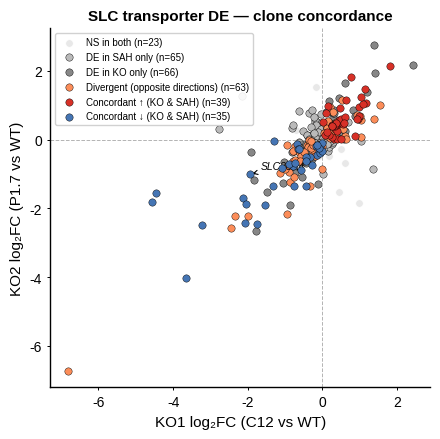

Saved: Explore_KO_clone_concordance_scatter.pdf


In [7]:
# ── Clone concordance scatter ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(4.5, 4.5))

colors_map = {
    'concordant_down': '#4575B4',
    'concordant_up':   '#D73027',
    'divergent':       '#FC8D59',
    'KO_only':         '#878787',
    'SAH_only':        '#BABABA',
    'ns_both':         '#E8E8E8',
}
labels_map = {
    'concordant_down': 'Concordant ↓ (KO & SAH)',
    'concordant_up':   'Concordant ↑ (KO & SAH)',
    'divergent':       'Divergent (opposite directions)',
    'KO_only':         'DE in KO only',
    'SAH_only':        'DE in SAH only',
    'ns_both':         'NS in both',
}
zorder_map = {'ns_both': 1, 'SAH_only': 2, 'KO_only': 2, 'divergent': 3,
              'concordant_up': 4, 'concordant_down': 4}

for cat in ['ns_both', 'SAH_only', 'KO_only', 'divergent', 'concordant_up', 'concordant_down']:
    sub = df[df['concordance'] == cat]
    ax.scatter(sub['KO1_logFC'], sub['KO2_logFC'],
               color=colors_map[cat], edgecolors='white' if cat == 'ns_both' else 'black',
               linewidths=0.3, s=28, zorder=zorder_map[cat], label=f"{labels_map[cat]} (n={len(sub)})")

# Annotate SLC38A4
slc38a4 = df[df['symbol'] == 'SLC38A4']
if len(slc38a4):
    r = slc38a4.iloc[0]
    ax.annotate('SLC38A4', (r['KO1_logFC'], r['KO2_logFC']),
                xytext=(8, 4), textcoords='offset points', fontsize=7.5,
                fontstyle='italic', arrowprops=dict(arrowstyle='->', lw=0.8))

ax.axhline(0, color='0.7', lw=0.7, ls='--')
ax.axvline(0, color='0.7', lw=0.7, ls='--')
ax.set_xlabel('KO1 log₂FC (C12 vs WT)', fontsize=11)
ax.set_ylabel('KO2 log₂FC (P1.7 vs WT)', fontsize=11)
ax.set_title('SLC transporter DE — clone concordance', fontsize=11, fontweight='bold')
ax.legend(fontsize=7, frameon=True, framealpha=0.9, edgecolor='0.8', loc='upper left')
plt.tight_layout()
fig.savefig('Explore_KO_clone_concordance_scatter.pdf', bbox_inches='tight')
plt.show()
print('Saved: Explore_KO_clone_concordance_scatter.pdf')


# Exploratory analysis 3 · All differentially expressed SLC transporters

Paired bar chart (KO log₂FC / SAH log₂FC) for every SLC gene that is DE in at least one comparison
(KO-concordant or SAH FDR < 0.05), ranked by SAH log₂FC.  Faded bars = FDR ≥ 0.05 in that
comparison.  Genes are colour-coded by concordance category.

In [8]:
# ── Select DE genes from either comparison ────────────────────────────────
deg = df[(df['KO_DE'] | df['SAH_sig'])].copy()
deg = deg.sort_values('SAH_log2FC').reset_index(drop=True)
n = len(deg)
print(f"DE in KO or SAH: {n} genes")
print(deg[['symbol', 'concordance', 'KO1_logFC', 'KO2_logFC',
           'SAH_log2FC', 'KO1_FDR', 'KO2_FDR', 'SAH_padj']].round(3).to_string())


DE in KO or SAH: 268 genes
       symbol      concordance  KO1_logFC  KO2_logFC  SAH_log2FC  KO1_FDR  KO2_FDR  SAH_padj
0     SLC5A12  concordant_down     -0.781     -0.764      -3.464    0.000    0.000     0.000
1    SLC16A10        divergent      0.135      0.109      -3.111    0.030    0.079     0.000
2     SLC17A8  concordant_down     -1.073     -0.824      -2.799    0.002    0.009     0.000
3        RHBG        divergent      1.026      0.065      -2.787    0.000    0.731     0.000
4     SLCO1B3         SAH_only      1.368     -0.859      -2.636    0.000    0.002     0.000
5     SLC19A2  concordant_down     -0.081     -0.326      -2.437    0.323    0.000     0.000
6     SLC6A13         SAH_only     -2.168      1.268      -2.435    0.006    0.011     0.000
7     SLC38A4  concordant_down     -1.949     -1.015      -2.350    0.000    0.000     0.000
8     SLC47A1  concordant_down     -0.434     -0.495      -2.283    0.000    0.000     0.000
9      UNC93A  concordant_down     -1.286  



Saved: Explore_all_DEG_SLCs.pdf


In [9]:
# ── Paired horizontal bar chart — all DEG SLCs ───────────────────────────
C_KO, C_SAH = '#E08214', '#8073AC'

deg = df[(df['KO_DE'] | df['SAH_sig'])].copy()
deg = deg.sort_values('SAH_log2FC').reset_index(drop=True)
n = len(deg)

# Use mean of KO1 and KO2 logFC as the KO bar (mirrors the combined KO_logFC in the annotation table)
deg['KO_mean_logFC'] = (deg['KO1_logFC'] + deg['KO2_logFC']) / 2
# KO bar is faded if neither clone is significant
deg['KO_alpha'] = np.where(deg['KO_DE'], 1.0, 0.28)
deg['SAH_alpha'] = np.where(deg['SAH_sig'], 1.0, 0.28)

y = np.arange(n)
h = 0.38

fig_h = max(6, 0.38 * n + 1.5)
fig, ax = plt.subplots(figsize=(6.5, fig_h))

for i, row in deg.iterrows():
    ax.barh(i + h/2, row['KO_mean_logFC'], height=h,
            color=to_rgba(C_KO,  row['KO_alpha']),  edgecolor='black', lw=0.35)
    ax.barh(i - h/2, row['SAH_log2FC'], height=h,
            color=to_rgba(C_SAH, row['SAH_alpha']), edgecolor='black', lw=0.35)

ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(deg['symbol'], fontsize=7.5, fontstyle='italic')
ax.set_xlabel('log₂ fold-change', fontsize=11)
ax.set_title(f'All DE SLC transporters (n={n})\nKO: concordant clones; SAH: InTEAM DESeq2',
             fontsize=10, fontweight='bold', pad=8)
ax.set_ylim(-0.7, n - 0.3)

# Colour-code y-tick labels by concordance
concordance_colours = {
    'concordant_down': '#4575B4',
    'concordant_up':   '#D73027',
    'divergent':       '#E07010',
    'KO_only':         '#555555',
    'SAH_only':        '#8073AC',
    'ns_both':         '#AAAAAA',
}
for tick, (_, row) in zip(ax.get_yticklabels(), deg.iterrows()):
    tick.set_color(concordance_colours.get(row['concordance'], 'black'))

legend_patches = [
    mpatches.Patch(color=C_KO,  label='KO mean log₂FC (KO1 + KO2)'),
    mpatches.Patch(color=C_SAH, label='SAH log₂FC (InTEAM)'),
    mpatches.Patch(facecolor='0.7', alpha=0.35, edgecolor='0.5', label='faded = FDR ≥ 0.05'),
]
concordance_leg = [
    mpatches.Patch(color='#4575B4', label='Concordant ↓'),
    mpatches.Patch(color='#D73027', label='Concordant ↑'),
    mpatches.Patch(color='#E07010', label='Divergent'),
    mpatches.Patch(color='#555555', label='KO only'),
    mpatches.Patch(color='#8073AC', label='SAH only'),
]
l1 = ax.legend(handles=legend_patches, fontsize=7.5, frameon=False,
               loc='lower right', bbox_to_anchor=(1.0, 0.0))
ax.add_artist(l1)
ax.legend(handles=concordance_leg, title='Gene label colour', title_fontsize=7,
          fontsize=7.5, frameon=False, loc='upper left')

plt.tight_layout()
fig.savefig('Explore_all_DEG_SLCs.pdf', bbox_inches='tight')
plt.show()
print('Saved: Explore_all_DEG_SLCs.pdf')


## Breakdown by substrate class and concordance

In [10]:
deg = df[(df['KO_DE'] | df['SAH_sig'])].copy()

print("=== Concordance × substrate class:")
ct = pd.crosstab(deg['substrate class'], deg['concordance'])
print(ct.to_string())

print("\n=== Concordance × SLC family (top families):")
ct2 = pd.crosstab(deg['family'], deg['concordance'])
ct2['total'] = ct2.sum(axis=1)
print(ct2.sort_values('total', ascending=False).head(20).to_string())


=== Concordance × substrate class:
concordance                                     KO_only  SAH_only  concordant_down  concordant_up  divergent
substrate class                                                                                             
amino acids, peptides and derivatives                10         7               11              5         12
auxiliary subunits / insertases / pseudogenes         2         1                0              0          0
carbohydrates and derivatives                         5         3                2              2          6
carboxylic acids and derivatives                      4         2                6              2          5
heteroarenes                                          2         3                2              2          1
inorganic ions                                        3        10                2              3          7
lipids and steroids                                   0         6                1           

# Exploratory analysis 4 · System A and System N transporters — complete SLC38 family

Source: UniProt reviewed human entries (SLC38A1–A12), cross-referenced against KO RNA-seq and
InTEAM SAH DESeq2.

**System classification (confirmed against UniProt reviewed entries):**
| Gene | SNAT | System | Localisation |
|------|------|--------|--------------|
| SLC38A1 | SNAT1 | **A** | Plasma membrane |
| SLC38A2 | SNAT2 | **A** | Plasma membrane |
| SLC38A3 | SNAT3 | **N** | Plasma membrane (basolateral) |
| SLC38A4 | SNAT4 | **A** | Plasma membrane |
| SLC38A5 | SNAT5 | **N** | Plasma membrane |
| SLC38A6 | SNAT6 | **N** | Plasma membrane (synaptic) |
| SLC38A7 | SNAT7 | — | Lysosome |
| SLC38A8 | — | — | Plasma membrane / cytoplasm |
| SLC38A9 | — | — | Lysosome / late endosome |
| SLC38A10 | — | — | Membrane (general) |
| SLC38A11 | — | — | Membrane (general) |
| SLC38A12 | — | — | Membrane (general) |

System A = Na⁺-coupled, MeAIB-sensitive, plasma membrane, prefer Ala/Ser/Gln (SLC38A1/A2/A4).  
System N = Na⁺/H⁺-coupled, bidirectional, prefer Gln/Asn/His (SLC38A3/A5; SLC38A6 in CNS).  
Non-System A/N members (A7–A12) are poorly characterised or intracellular — excluded from the
"System A/N" comparison in the main figure panel.

**Confirmed by UniProt search:** No non-SLC38 human genes carry a "System A" transporter
designation in reviewed SwissProt entries.

Data: `FigS7_limma_KO1_vs_WT_mincount10.csv`, `FigS7_limma_KO2_vs_WT_mincount10.csv`,
`InTEAM_AH_vs_normal_DESeq2.csv` (measured-in-KO/SAH flags derived directly from presence
in these tables).

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import to_rgba

plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 10, 'axes.linewidth': 1.0,
    'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'axes.unicode_minus': False,
})

# ── System classification (UniProt-derived, reviewed human entries) ────────
SLC38_META = {
    'SLC38A1': {'snat': 'SNAT1', 'system': 'A',   'location': 'plasma membrane'},
    'SLC38A2': {'snat': 'SNAT2', 'system': 'A',   'location': 'plasma membrane'},
    'SLC38A3': {'snat': 'SNAT3', 'system': 'N',   'location': 'plasma membrane'},
    'SLC38A4': {'snat': 'SNAT4', 'system': 'A',   'location': 'plasma membrane'},
    'SLC38A5': {'snat': 'SNAT5', 'system': 'N',   'location': 'plasma membrane'},
    'SLC38A6': {'snat': 'SNAT6', 'system': 'N',   'location': 'plasma membrane (synaptic)'},
    'SLC38A7': {'snat': 'SNAT7', 'system': None,  'location': 'lysosome'},
    'SLC38A8': {'snat': None,    'system': None,  'location': 'plasma membrane/cytoplasm'},
    'SLC38A9': {'snat': None,    'system': None,  'location': 'lysosome/endosome'},
    'SLC38A10':{'snat': None,    'system': None,  'location': 'membrane'},
    'SLC38A11':{'snat': None,    'system': None,  'location': 'membrane'},
    'SLC38A12':{'snat': None,    'system': None,  'location': 'membrane'},
}

# ── Load DE data ──────────────────────────────────────────────────────────
ko1 = (pd.read_csv('FigS7_limma_KO1_vs_WT_mincount10.csv')
       .rename(columns={'gene_symbol':'symbol','logFC':'KO1_logFC','adj.P.Val':'KO1_FDR'})
       [['symbol','KO1_logFC','KO1_FDR']].drop_duplicates('symbol'))
ko2 = (pd.read_csv('FigS7_limma_KO2_vs_WT_mincount10.csv')
       .rename(columns={'gene_symbol':'symbol','logFC':'KO2_logFC','adj.P.Val':'KO2_FDR'})
       [['symbol','KO2_logFC','KO2_FDR']].drop_duplicates('symbol'))
sah = (pd.read_csv('InTEAM_AH_vs_normal_DESeq2.csv')
       .rename(columns={'log2FoldChange':'SAH_log2FC','padj':'SAH_padj'})
       [['symbol','SAH_log2FC','SAH_padj']].drop_duplicates('symbol'))

# Build SLC38 table (all 12 members)
rows = []
for gene, meta in SLC38_META.items():
    r = {'symbol': gene, 'snat': meta['snat'],
         'system': meta['system'], 'location': meta['location']}
    # KO data
    for df_, cols in [(ko1, ['KO1_logFC','KO1_FDR']),
                      (ko2, ['KO2_logFC','KO2_FDR']),
                      (sah, ['SAH_log2FC','SAH_padj'])]:
        hit = df_[df_['symbol'] == gene]
        for c in cols:
            r[c] = hit[c].values[0] if len(hit) else np.nan
    # Measured flags -- derived directly from presence in the per-clone KO / SAH tables above
    r['measured_KO']  = (gene in ko1['symbol'].values) or (gene in ko2['symbol'].values)
    r['measured_SAH'] = gene in sah['symbol'].values
    rows.append(r)

slc38 = pd.DataFrame(rows)
slc38['KO_mean_logFC'] = (slc38['KO1_logFC'] + slc38['KO2_logFC']) / 2
slc38['KO_concordant'] = (np.sign(slc38['KO1_logFC']) == np.sign(slc38['KO2_logFC']))
slc38 = slc38.sort_values('SAH_log2FC').reset_index(drop=True)

FDR = 0.05
slc38['KO1_sig'] = slc38['KO1_FDR'] < FDR
slc38['KO2_sig'] = slc38['KO2_FDR'] < FDR
slc38['SAH_sig'] = slc38['SAH_padj'] < FDR
slc38['KO_DE'] = (slc38['KO1_sig'] | slc38['KO2_sig']) & slc38['KO_concordant']

print("=== Full SLC38 family DE summary ===")
display(slc38[['symbol','snat','system','location','measured_KO','measured_SAH',
               'KO1_logFC','KO1_FDR','KO2_logFC','KO2_FDR',
               'KO_DE','SAH_log2FC','SAH_padj','SAH_sig']].round(3))


=== Full SLC38 family DE summary ===


,symbol,snat,system,location,measured_KO,measured_SAH,KO1_logFC,KO1_FDR,KO2_logFC,KO2_FDR,KO_DE,SAH_log2FC,SAH_padj,SAH_sig
0,SLC38A4,SNAT4,A,plasma membrane,True,True,-1.949,0.000,-1.015,0.000,True,-2.350,0.000,True
1,SLC38A3,SNAT3,N,plasma membrane,True,True,-0.760,0.000,-1.343,0.000,True,-0.899,0.000,True
2,SLC38A11,None,None,membrane,True,True,0.618,0.016,0.007,0.982,True,-0.807,0.000,True
3,SLC38A2,SNAT2,A,plasma membrane,True,True,-0.746,0.000,-0.965,0.000,True,-0.225,0.401,False
4,SLC38A9,None,None,lysosome/endosome,True,True,-1.060,0.000,-1.265,0.000,True,0.162,0.050,False
5,SLC38A10,None,None,membrane,True,True,0.337,0.000,0.419,0.000,True,0.356,0.012,True
6,SLC38A8,None,None,plasma membrane/cytoplasm,False,True,NaN,NaN,NaN,NaN,False,0.774,NaN,False
7,SLC38A7,SNAT7,None,lysosome,True,True,-0.395,0.000,-0.224,0.018,True,0.833,0.000,True
8,SLC38A6,SNAT6,N,plasma membrane (synaptic),True,True,-0.159,0.009,0.069,0.226,False,1.231,0.000,True
9,SLC38A5,SNAT5,N,plasma membrane,False,True,NaN,NaN,NaN,NaN,False,1.274,0.002,True


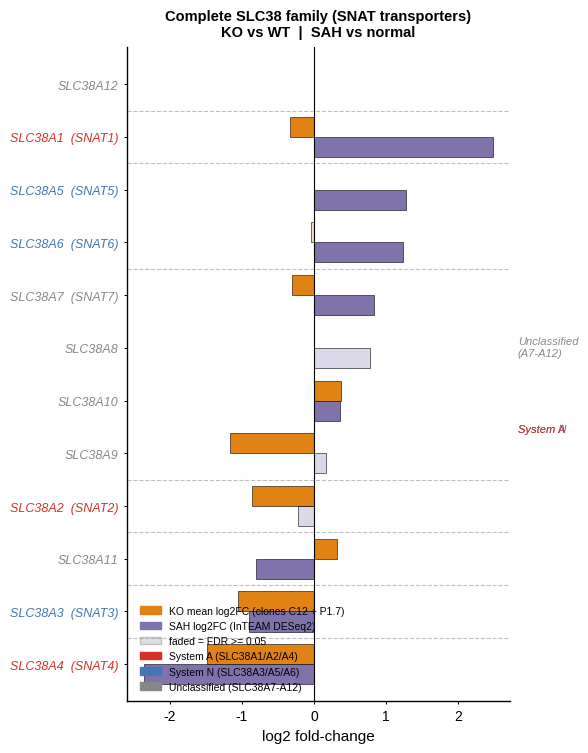

Saved: Explore_SLC38_SystemAN_complete.pdf


In [12]:
# ── Paired bar chart: all 12 SLC38 members ───────────────────────────────
C_KO, C_SAH = '#E08214', '#8073AC'
SYS_COLORS = {'A': '#D73027', 'N': '#4575B4', None: '#888888'}

n = len(slc38)
y = np.arange(n)
h = 0.38

fig, ax = plt.subplots(figsize=(6.0, 0.52 * n + 1.4))

for i, row in slc38.iterrows():
    ko_alpha  = 1.0 if row['KO_DE']  else 0.28
    sah_alpha = 1.0 if row['SAH_sig'] else 0.28
    ax.barh(i + h/2, row['KO_mean_logFC'], height=h,
            color=to_rgba(C_KO,  ko_alpha),  edgecolor='black', lw=0.4)
    ax.barh(i - h/2, row['SAH_log2FC'],     height=h,
            color=to_rgba(C_SAH, sah_alpha), edgecolor='black', lw=0.4)

ax.axvline(0, color='black', lw=0.8)

# Y-tick labels: gene name + SNAT alias
ytick_labels = []
for _, row in slc38.iterrows():
    label = row['symbol']
    if pd.notna(row['snat']):
        label += '  (' + row['snat'] + ')'
    ytick_labels.append(label)
ax.set_yticks(y)
ax.set_yticklabels(ytick_labels, fontsize=9, fontstyle='italic')

# Colour y-tick labels by transport system
for tick, (_, row) in zip(ax.get_yticklabels(), slc38.iterrows()):
    tick.set_color(SYS_COLORS.get(row['system'] if pd.notna(row['system']) else None, '#888888'))

# Group separator lines
prev_sys = '__start__'
for i, (_, row) in enumerate(slc38.iterrows()):
    if row['system'] != prev_sys and prev_sys != '__start__':
        ax.axhline(i - 0.5, color='0.75', lw=0.8, ls='--')
    prev_sys = row['system']

# Right-margin system annotations
groups = [
    (slc38[slc38['system'].isna()].index.tolist(),   None, 'Unclassified\n(A7-A12)'),
    (slc38[slc38['system'] == 'N'].index.tolist(),   'N',  'System N'),
    (slc38[slc38['system'] == 'A'].index.tolist(),   'A',  'System A'),
]
for idxs, sys, label in groups:
    if idxs:
        mid = (min(idxs) + max(idxs)) / 2
        ax.text(1.02, mid / n, label, transform=ax.transAxes,
                fontsize=8, va='center', ha='left',
                color=SYS_COLORS[sys], fontstyle='italic')

ax.set_xlabel('log2 fold-change', fontsize=11)
ax.set_title('Complete SLC38 family (SNAT transporters)\nKO vs WT  |  SAH vs normal',
             fontsize=10.5, fontweight='bold', pad=8)
ax.set_ylim(-0.7, n - 0.3)

legend_patches = [
    mpatches.Patch(color=C_KO,  label='KO mean log2FC (clones C12 + P1.7)'),
    mpatches.Patch(color=C_SAH, label='SAH log2FC (InTEAM DESeq2)'),
    mpatches.Patch(facecolor='0.7', alpha=0.4, edgecolor='0.5', label='faded = FDR >= 0.05'),
    mpatches.Patch(color=SYS_COLORS['A'], label='System A (SLC38A1/A2/A4)'),
    mpatches.Patch(color=SYS_COLORS['N'], label='System N (SLC38A3/A5/A6)'),
    mpatches.Patch(color=SYS_COLORS[None], label='Unclassified (SLC38A7-A12)'),
]
ax.legend(handles=legend_patches, fontsize=7.5, frameon=False,
          loc='lower left', bbox_to_anchor=(0.01, 0.0))

plt.tight_layout()
fig.savefig('Explore_SLC38_SystemAN_complete.pdf', bbox_inches='tight')
plt.show()
print('Saved: Explore_SLC38_SystemAN_complete.pdf')
